# 01 · A ontologia central de manufatura

**Objetivo:** entender as três peças da camada semântica e construir a primeira delas, a **ontologia central**.

| Peça | O que é | Neste repositório |
|---|---|---|
| **Ontologia** | o vocabulário: classes, relações e regras | `ontology/*.ttl` |
| **Grafo de conhecimento** | os fatos da planta descritos com esse vocabulário | `data/plant.ttl` |
| **Contratos de dados** | o que um registro precisa ter para entrar no grafo | `shapes/shapes.ttl` (notebook 03) |

A ontologia central é pequena de propósito: só o que **todos** os domínios precisam. Hierarquia ISA-95, pontos de dado e eventos. Produção, manutenção, qualidade, energia e estoque vêm depois, como **extensões** (notebook 02).

### Antes de começar

| | |
|---|---|
| **Para quem** | Quem trabalha com dados de fábrica e nunca usou RDF, OWL ou grafos de conhecimento. |
| **Pré-requisitos** | Python básico e noção da hierarquia ISA-95 (empresa, planta, área, linha, máquina). Nenhum conhecimento de RDF. |
| **Tempo** | 35 minutos |

**Ao final você consegue:**

- Ler uma tripla RDF e dizer quem é sujeito, predicado e objeto.
- Diferenciar classe, instância, relação entre coisas e atributo com valor.
- Explicar o que `subClassOf` e uma propriedade transitiva permitem perguntar.
- Escrever uma consulta que encontra tudo o que existe dentro de uma planta.

**Onde isso aparece na fábrica:** MES, CMMS, qualidade e energia chamam a mesma máquina por nomes diferentes. Uma ontologia central é o acordo sobre identidade e hierarquia que permite cruzar esses sistemas.

**Uma analogia para guardar:** A ontologia é a gramática e o dicionário; o grafo é o texto escrito com eles. Primeiro se combina o que significam "máquina", "faz parte de" e "ponto de dado"; depois se descreve a fábrica usando só essas palavras.

> **Como estudar:** rode uma célula por vez. Sempre que aparecer **Pare e preveja**, responda mentalmente antes de executar. Errar a previsão é o que faz o conceito fixar.

In [1]:
# Configuração: deixa a raiz do repositório no caminho de import
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))
import pandas as pd
pd.set_option("display.max_colwidth", 80)
from lab.graph import load_ontology, load_plant, query, MFG, PRD, MNT, QA, NRG, INV, ID

## 1. Carregando a ontologia central

O arquivo está em **Turtle**, o formato texto do RDF. Cada linha é uma tripla `sujeito predicado objeto`.

In [2]:
core = load_ontology(domains=[])
print(f"{len(core)} triplas na ontologia central\n")
texto = open("../ontology/core.ttl", encoding="utf-8").read()
print(texto[texto.index("mfg:Asset a owl:Class"):][:1500])

201 triplas na ontologia central

mfg:Asset a owl:Class ;
    rdfs:label "Asset" ;
    rdfs:comment "Anything in the equipment hierarchy that has a stable identity." ;
    skos:example "a site, a packaging line, a filler, a seal kit" ;
    mfg:isAbstract true .

mfg:Enterprise a owl:Class ; rdfs:subClassOf mfg:Asset ; rdfs:label "Enterprise" ;
    rdfs:comment "The company as a whole, the root of the hierarchy." ;
    skos:example "ACME Beverages" .

mfg:Site a owl:Class ; rdfs:subClassOf mfg:Asset ; rdfs:label "Site" ;
    rdfs:comment "A plant at one geographic location." ;
    skos:example "São Paulo plant, Curitiba plant" .

mfg:Area a owl:Class ; rdfs:subClassOf mfg:Asset ; rdfs:label "Area" ;
    rdfs:comment "A part of a site organized around one kind of work." ;
    skos:example "packaging, utilities, warehouse" .

mfg:Line a owl:Class ; rdfs:subClassOf mfg:Asset ; rdfs:label "Production line" ;
    rdfs:comment "A set of equipment arranged to make product in sequence. Orders a

## 2. As classes e a hierarquia de classes

> **Pare e preveja.** Linha, máquina e planta são coisas bem diferentes. Mesmo assim, o que elas têm em comum que justificaria uma classe mãe?

In [3]:
classes = query(core, '''
SELECT ?classe ?mae ?descricao WHERE {
  ?c a <http://www.w3.org/2002/07/owl#Class> ; rdfs:label ?classe .
  OPTIONAL { ?c rdfs:subClassOf/rdfs:label ?mae }
  OPTIONAL { ?c rdfs:comment ?descricao }
} ORDER BY ?mae ?classe''')
pd.DataFrame(classes)

,classe,descricao,mae
0,Asset,Anything in the equipment hierarchy that has a stable identity.,NaN
1,Capability,"Something an equipment is able to do, stated independently of any product or...",NaN
2,Data point,"A measured or derived value that belongs to an asset: a PLC tag, a sensor re...",NaN
3,Equipment class,"A catalogue entry for a kind of equipment. It describes the type, while Equi...",NaN
4,Event,Something that happened to an asset over a period of time. Every domain even...,NaN
5,Operating state,"One of the harmonized states every equipment reports, whatever its vendor ca...",NaN
6,Person,Someone who performs or is accountable for work in the plant.,NaN
7,Role,A function a person performs. Kept apart from the person because people chan...,NaN
8,Area,A part of a site organized around one kind of work.,Asset
9,Enterprise,"The company as a whole, the root of the hierarchy.",Asset


**Leitura:** `Enterprise`, `Site`, `Area`, `Line` e `Equipment` são todos subclasses de `Asset`. Isso permite perguntar "todos os ativos" sem listar os cinco tipos, e garante que qualquer coisa da hierarquia tenha um `assetId`.

`StateChange` é subclasse de `Event`: toda extensão que criar um evento novo (parada, ordem de produção, inspeção) herda `occurredOn`, `startTime` e `endTime`.

## 3. As relações (propriedades)

In [4]:
props = query(core, '''
SELECT ?propriedade ?tipo ?de ?para WHERE {
  ?p rdfs:label ?propriedade ; a ?t .
  FILTER(?t IN (<http://www.w3.org/2002/07/owl#ObjectProperty>, <http://www.w3.org/2002/07/owl#DatatypeProperty>))
  BIND(STRAFTER(STR(?t), "#") AS ?tipo)
  OPTIONAL { ?p rdfs:domain/rdfs:label ?de }
  OPTIONAL { ?p rdfs:range ?r . BIND(REPLACE(STR(?r), "^.*[#/]", "") AS ?para) }
} ORDER BY ?tipo ?propriedade''')
pd.DataFrame(props)

,propriedade,tipo,de,para
0,UNS topic,DatatypeProperty,Data point,string
1,asset id,DatatypeProperty,Asset,string
2,end time,DatatypeProperty,Event,dateTime
3,is productive,DatatypeProperty,Operating state,boolean
4,last update,DatatypeProperty,Data point,dateTime
5,last value,DatatypeProperty,Data point,Literal
6,start time,DatatypeProperty,Event,dateTime
7,to state,DatatypeProperty,State change,string
8,unit,DatatypeProperty,Data point,string
9,can transition to,ObjectProperty,Operating state,OperatingState


* **ObjectProperty** liga duas coisas (`partOf` liga um ativo a outro ativo).
* **DatatypeProperty** liga uma coisa a um valor (`unsTopic` liga um ponto de dado a uma string).
* `partOf` é **transitiva**: se a enchedora é parte da linha 1 e a linha 1 é parte da área de envase, a enchedora também é parte da área. Isso evita gravar todas as relações indiretas.

## 4. A ontologia aplicada: a planta de exemplo

Agora carregamos os **fatos** (`data/plant.ttl`) sobre o vocabulário. Uma empresa fictícia com duas plantas, três linhas e três máquinas por linha.

In [5]:
g = load_plant()
print(f"{len(g)} triplas (ontologia + dados)")
ativos = query(g, '''
SELECT ?tipo (COUNT(?a) AS ?quantidade) WHERE {
  ?a a ?c . ?c rdfs:subClassOf* mfg:Asset ; rdfs:label ?tipo .
  FILTER(STRSTARTS(STR(?a), STR(id:)))
} GROUP BY ?tipo ORDER BY DESC(?quantidade)''')
pd.DataFrame(ativos)

1386 triplas (ontologia + dados)


,tipo,quantidade
0,Equipment,9
1,Production line,3
2,Component,3
3,Site,2
4,Area,2
5,Enterprise,1


Repare em `rdfs:subClassOf*`: o asterisco percorre a hierarquia de classes, então `Component` (definido na extensão de manutenção) entra na conta como ativo sem que a consulta precise saber que ele existe.

## 5. A hierarquia ISA-95 como grafo

digraph H { rankdir=TB; nodesep=0.25; ranksep=0.45;
node [shape=box style="rounded,filled" fontname="Helvetica" fontsize=10 fontcolor=white];
edge [color="#999999" arrowhead=none];
"https://w3id.org/industrial-ontology-lab/id/acme/curitiba/packaging/line-3/capper-01" [label="Capper L3\nEquipment" fillcolor="#7f8c8d"];
"https://w3id.org/industrial-ontology-lab/id/acme/curitiba/packaging/line-3/labe ...


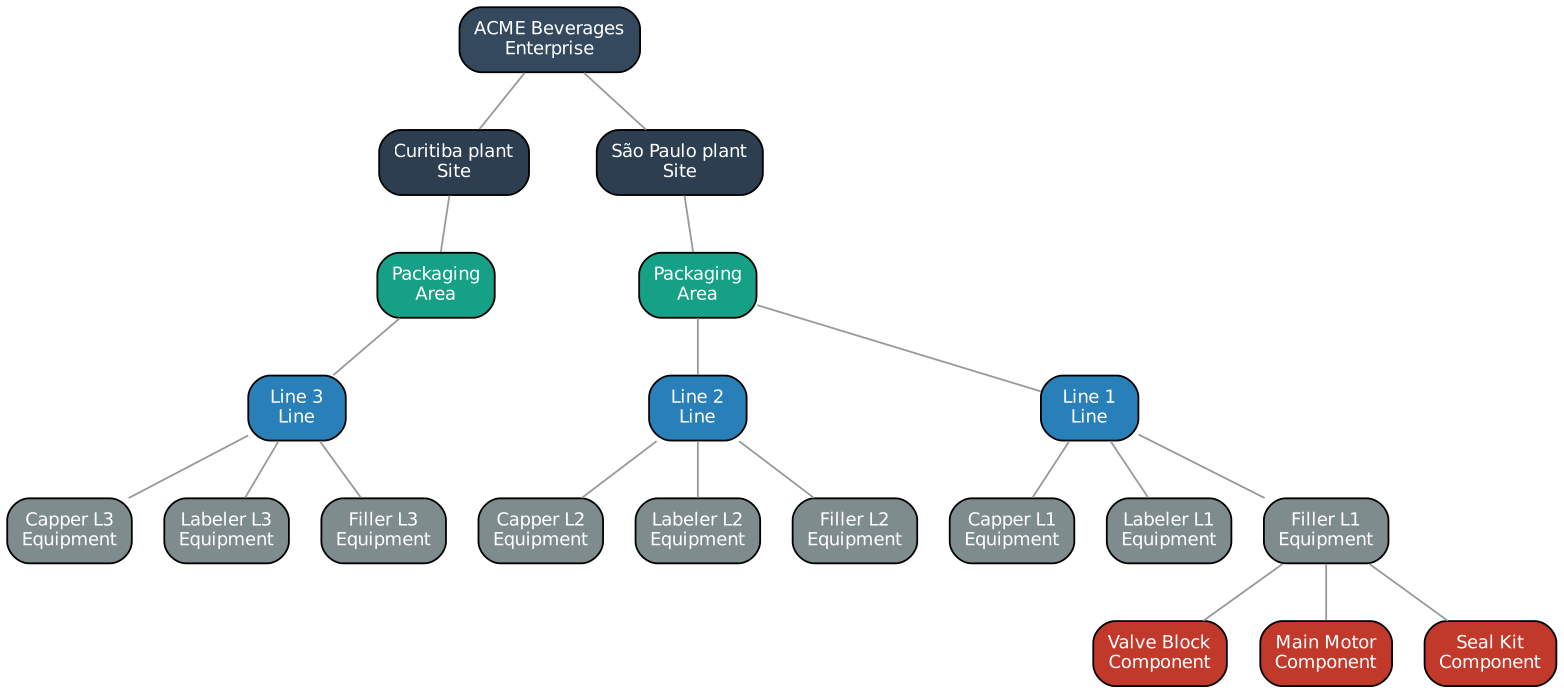

In [6]:
# A figura é gerada em DOT (Graphviz) a partir das triplas mfg:partOf. Veja lab/figures.py
from IPython.display import Image
from lab import figures
print(figures.hierarchy_dot(g)[:400], "...")
Image(filename=figures.render(figures.hierarchy_dot(g), "hierarchy"))

**Leitura:** cada caixa é um ativo, a cor indica o nível ISA-95, e cada traço é uma tripla `filho mfg:partOf pai`. Os três componentes vermelhos ficam abaixo da enchedora da linha 1: é ali que a manutenção registra trocas de peça.

## 6. Transitividade na prática

Pergunta: **"tudo o que existe na planta de São Paulo"**. Ninguém gravou "enchedora partOf São Paulo"; o caminho `partOf+` (um ou mais saltos) encontra.

> **Pare e preveja.** Ninguém gravou a frase "o kit de vedação faz parte da planta de São Paulo". A consulta com `partOf+` vai encontrá-lo mesmo assim?

In [7]:
from lab import queries as q
pd.DataFrame(query(g, q.ASSETS_IN_SITE)).assign(asset=lambda d: d.asset.str.split("/id/").str[1], type=lambda d: d.type.str.split("#").str[1])

,asset,type,label
0,acme/sao-paulo/packaging,Area,Packaging
1,acme/sao-paulo/packaging/line-1,Line,Line 1
2,acme/sao-paulo/packaging/line-1/capper-01,Equipment,Capper L1
3,acme/sao-paulo/packaging/line-1/filler-01,Equipment,Filler L1
4,acme/sao-paulo/packaging/line-1/filler-01/main-motor,Component,Main Motor
5,acme/sao-paulo/packaging/line-1/filler-01/seal-kit,Component,Seal Kit
6,acme/sao-paulo/packaging/line-1/filler-01/valve-block,Component,Valve Block
7,acme/sao-paulo/packaging/line-1/labeler-01,Equipment,Labeler L1
8,acme/sao-paulo/packaging/line-2,Line,Line 2
9,acme/sao-paulo/packaging/line-2/capper-01,Equipment,Capper L2


São 12 ativos: a área, duas linhas, seis máquinas e três **componentes** da enchedora da linha 1, que vivem dois níveis abaixo da linha.

## Resumo

* A ontologia central define **identidade** (`assetId`), **contenção** (`partOf`, transitiva), **pontos de dado** (com o tópico do UNS) e **eventos**.
* Classes formam hierarquias (`subClassOf`), e consultas com `*` e `+` aproveitam isso sem conhecer cada tipo.
* Tudo que vier depois (produção, manutenção, qualidade...) **pendura** nesse núcleo, em vez de criar seu próprio modelo de máquina.

---
## Erros comuns

- **Confundir classe com instância.** `Equipment` é a ideia de máquina; `filler-01` é uma máquina. Regras ficam na classe, fatos na instância.
- **Gravar todas as relações indiretas.** Se `partOf` é transitiva, basta ligar cada item ao pai direto. O resto é inferido pela consulta.
- **Colocar tudo na ontologia central.** O núcleo deve ter só o que todos os domínios usam. O resto vai nas extensões (notebook 02).
- **Usar o nome do tag do CLP como identidade.** A identidade é o lugar e a função do ativo. O endereço do CLP é só de onde vem o valor.

## Teste seu entendimento

Responda antes de abrir cada resposta.

**1. Na tripla `filler-01 mfg:partOf line-1`, o que é cada parte?**

<details><summary>Ver resposta</summary>

`filler-01` é o sujeito, `mfg:partOf` é o predicado (a relação) e `line-1` é o objeto.

</details>

**2. Qual a diferença entre ObjectProperty e DatatypeProperty?**

<details><summary>Ver resposta</summary>

ObjectProperty liga duas coisas do grafo (máquina a linha). DatatypeProperty liga uma coisa a um valor literal (ponto de dado a uma string de tópico).

</details>

**3. O que muda numa consulta quando se troca `partOf` por `partOf+`?**

<details><summary>Ver resposta</summary>

Sem o sinal, só os filhos diretos são encontrados. Com `+`, a consulta segue um ou mais saltos e encontra netos, bisnetos e assim por diante.

</details>

## Exercícios para praticar

1. Altere a consulta final para listar o que existe dentro da planta de Curitiba.
2. Escreva uma consulta que conte quantos pontos de dado (`DataPoint`) cada linha tem, somando os das suas máquinas.
3. Abra `ontology/core.ttl` e acrescente uma classe `Cell` entre `Line` e `Equipment`. O que precisaria mudar nos dados?

## Glossário

| Termo | Significado |
|---|---|
| **RDF** | Modelo de dados em que tudo é descrito por triplas sujeito, predicado, objeto. |
| **Turtle (.ttl)** | Formato de texto legível para escrever RDF. |
| **OWL** | Linguagem para definir classes, propriedades e suas características. |
| **IRI** | Identificador global de uma coisa, parecido com uma URL. |
| **Classe / instância** | A categoria e um membro dela. |
| **Propriedade transitiva** | Se A se relaciona com B e B com C, então A se relaciona com C. |
| **SPARQL** | Linguagem de consulta para grafos RDF. |

**Próximo passo:** [02 · Extensões de domínio](02_extensoes_de_dominio.ipynb), onde produção, manutenção, qualidade, energia e estoque se penduram neste núcleo.